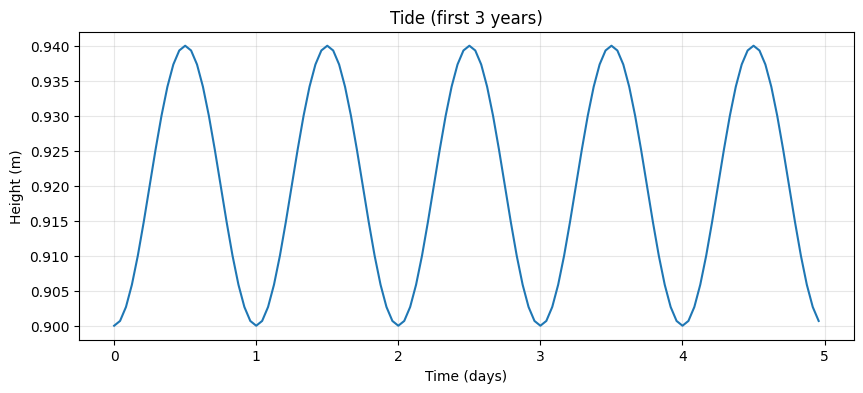

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#low tide at 0.9m, mean level at 0.92m

amplitude = 0.02 # meters
mean_level = 0.92 # meters
period_days = 1 # 1 high and 1 low tide per year
num_years = 10
days_per_year = 365.25
num_days = num_years * days_per_year
samples_per_day = 24

n_points = int(num_days * samples_per_day)
t = np.linspace(0, num_days, n_points)
h = mean_level - amplitude * np.cos(
    2 * np.pi * t / period_days
)

df = pd.DataFrame({
    "time_days": t,
    "height_m": h
})

# Plot to look at curve
window_days = 5
mask = t < window_days

plt.figure(figsize=(10, 4))
plt.plot(t[mask], h[mask])
plt.xlabel("Time (days)")
plt.ylabel("Height (m)")
plt.title("Tide (first 3 years)")
plt.grid(True, alpha=0.3)
plt.show()

# Save file as txt
output_path = "/Users/finleydavis/Desktop/CZN Project/HGS/_repo/tides/tides.txt"

df.to_csv(
    output_path,
    sep=" ",
    index=False,
    header=False,
    float_format="%.6f"
)


# Writes in a way HGS can read
def tide_height(t_days):
    return mean_level - amplitude * np.cos(
        2 * np.pi * t_days / period_days
    )

### Add storm surge

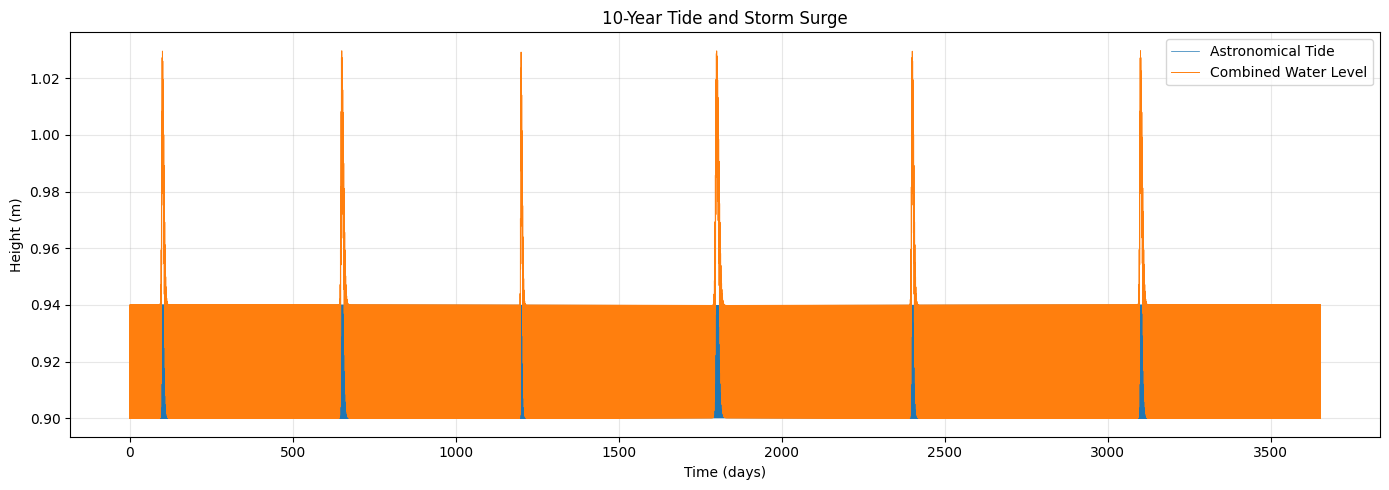

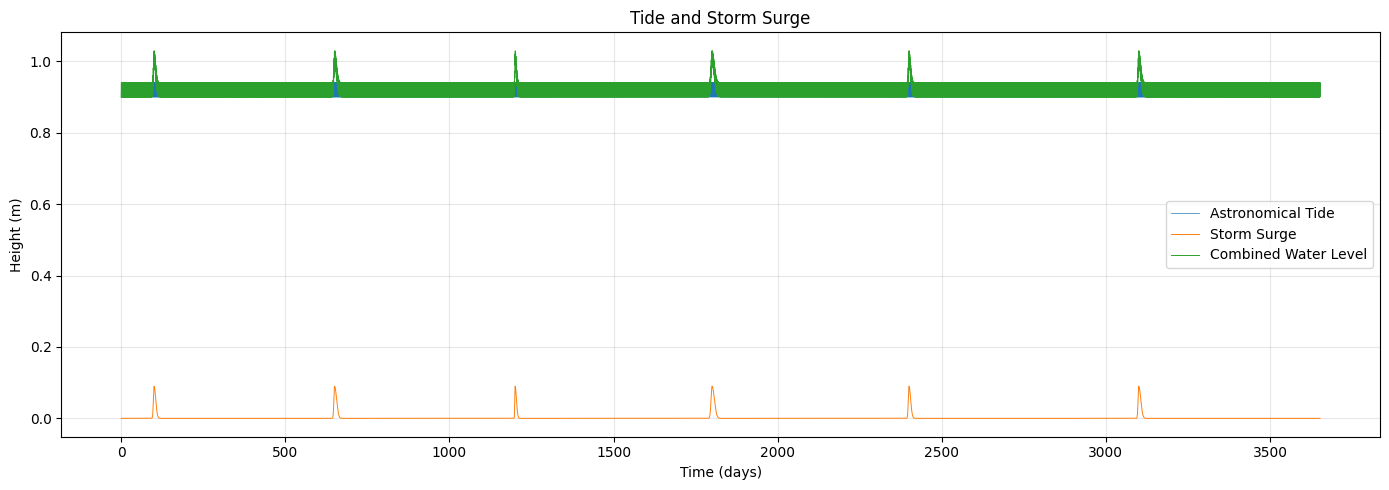

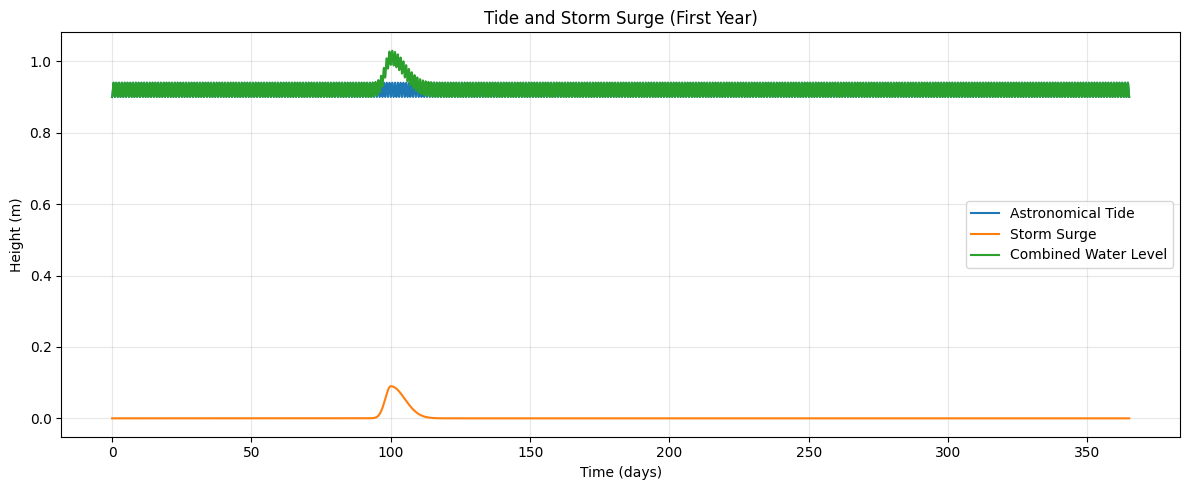

In [8]:
#same tides as above, but with storm surges added in.
#low tide at 0.9m, mean level at 0.92m
amplitude = 0.02 # meters
mean_level = 0.92 # meters
period_days = 1 # 1 high and 1 low tide per day
num_years = 10
days_per_year = 365.25
num_days = num_years * days_per_year
samples_per_day = 24

#************************************************************
#NOTE: EDIT BELOW HERE FOR STORM SURGE CHANGES *****************************
#************************************************************

#DOES NOT GEt HIGHER THAN 1.4m
#want surge not to be half a meter above high tide************

#storm surge parameters, these are random rn (synthetic too)
#format: (peak_day, peak_height, rise_duration, fall_duration)
storms = [
    (100, 0.09, 2, 5),
    (650, 0.09, 2, 6),
    (1200, 0.09, 1, 4),
    (1800, 0.09, 3, 7),
    (2400, 0.09, 2, 5),
    (3100, 0.09, 2, 6)
]

#generate time array
n_points = int(num_days * samples_per_day)
t = np.linspace(0, num_days, n_points)

#generate astronomical tide
tide = mean_level - amplitude * np.cos(
    2 * np.pi * t / period_days
)

#generate storm surges
surge = np.zeros_like(t)

#for params in storms, generate storm surge using Gaussian functions
for peak_day, peak_height, rise_duration, fall_duration in storms:

    #empty array for storm surge
    storm = np.zeros_like(t)

    #rapid rise before peak
    before_peak = t <= peak_day

    #add storm surge before peak
    storm[before_peak] = peak_height * np.exp(
        -0.5 * ((t[before_peak] - peak_day) / rise_duration)**2
    )

    # slower recession after peak, models physical phenomena of storm surge
    after_peak = t > peak_day

    #add storm surge after peak
    storm[after_peak] = peak_height * np.exp(
        -0.5 * ((t[after_peak] - peak_day) / fall_duration)**2
    )

    surge += storm

#combine tide and surge
h = tide + surge

#create df for output
df = pd.DataFrame({
    "time_days": t,
    "height_m": h
})

# plot entire 10 years, jusst visualizing the data, not for HGS
plt.figure(figsize = (14, 5))
plt.plot(t, tide, linewidth = 0.5, label = "Astronomical Tide")
plt.plot(t, h, linewidth = 0.7, label = "Combined Water Level")
plt.xlabel("Time (days)")
plt.ylabel("Height (m)")
plt.title("10-Year Tide and Storm Surge")
plt.legend()
plt.grid(True, alpha = 0.3)
plt.tight_layout()
plt.show()

# plot tide and surge separately
plt.figure(figsize = (14, 5))
plt.plot(t, tide, linewidth = 0.5, label = "Astronomical Tide")
plt.plot(t, surge, linewidth = 0.7, label = "Storm Surge")
plt.plot(t, h, linewidth = 0.7, label = "Combined Water Level")
plt.xlabel("Time (days)")
plt.ylabel("Height (m)")
plt.title("Tide and Storm Surge")
plt.legend()
plt.grid(True, alpha = 0.3)
plt.tight_layout()
plt.show()

# plot first year

window_days = 365
mask = t < window_days

plt.figure(figsize = (12, 5))
plt.plot(t[mask], tide[mask], label = "Astronomical Tide")
plt.plot(t[mask], surge[mask], label = "Storm Surge")
plt.plot(t[mask], h[mask], label = "Combined Water Level")
plt.xlabel("Time (days)")
plt.ylabel("Height (m)")
plt.title("Tide and Storm Surge (First Year)")
plt.legend()
plt.grid(True, alpha = 0.3)
plt.tight_layout()
plt.show()

# save file as txt in my repo
output_path = "/Users/finleydavis/Desktop/CZN Project/HGS/_repo/tides/tides_surge.txt"

df.to_csv(
    output_path,
    sep = " ",
    index = False,
    header = False,
    float_format = "%.6f"
)



In [5]:
#read txt file and plot to verify
